# 📊 ACTHO 360: Solución a los Resultados Esperados con `pandas`, `matplotlib` y `scikit-learn`

Este notebook resuelve de principio a fin los requerimientos del documento **"Lo que esperamos del tablero · Reto Estudia · Tablero Integral de Afiliados (Noviembre 2026)"** utilizando **`pandas`**, **`matplotlib`** y **`scikit-learn`** sobre las **7 tablas normalizadas** (`d:\analisis_exploratorio\data\normalizados\`):

1. **Carga y Vista Integrada del Modelo de Datos (`pandas`)**: Conexión de `dim_empresas`, `dim_personas`, `dim_eventos`, `dim_kams`, `fact_asistencias`, `fact_encuestas_satisfaccion` y `fact_movimientos_crm`.
2. **Frente 1 — Afiliación y Retención**: Afiliados activos por nivel (`Elite`, `Premium`, `Estándar`, `Personal`), segmento, sector, tamaño, ciudad, tasas de renovación/retiro y **curva de vencimientos a 30, 60 y 90 días por ejecutiva (KAM)**.
3. **Frente 2 — Participación y Adopción de Servicios**: Porcentaje de afiliados activos en servicios, identificación de quiénes **"pagan pero no participan"**, vulnerabilidad **monocontacto** y participación por línea 2027, formato y nivel de cargo.
4. **Frente 3 — Satisfacción, NPS y Temas Solicitados**: Calificación 1–5 por aspecto, cálculo del **NPS de Eventos y de ACTHO** y minería de texto (`TF-IDF` / frecuencias) sobre los comentarios de las encuestas.
5. **Frente 4 — Vista Integrada y Vista por Ejecutiva de Cuenta (KAM)**: Desempeño comparativo de las 6 carteras KAM y **Semáforo de Riesgo de No Renovación**.
6. **Frente 5 — Modelos de Machine Learning (`scikit-learn`)**:
   - **Modelo 1 (`RandomForestClassifier` vs `LogisticRegression`)**: Predicción de Deserción (*Churn Prediction*) con probabilidades e importancia de variables.
   - **Modelo 2 (`KMeans`)**: Segmentación no supervisada del comportamiento de los afiliados activos.
   - **Modelo 3 (`Cosine Similarity`)**: Sistema de recomendación personalizada de eventos 2027 para cada afiliado.
   - **Modelo 4 (`Lead Scoring`)**: Propensión de conversión de las **721 empresas no afiliadas** que asisten a eventos.
7. **Frente 6 — Exportación de las 8 Listas Accionables para Comunicaciones (Sección 05 del PDF)** y **Diccionario de Datos / Recomendaciones de Captura (Sección 06 del PDF)**.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]

NORM_DIR = r"d:\analisis_exploratorio\data\normalizados"
DUP_DIR = os.path.join(NORM_DIR, "duplicados")
SEG_DIR = os.path.join(NORM_DIR, "segmentos_comunicaciones")
os.makedirs(SEG_DIR, exist_ok=True)

try:
    from IPython.display import HTML, display
except ImportError:
    display = print
    HTML = str

if "mostrar_df" not in globals():
    def mostrar_df(df: pd.DataFrame, titulo: str = "", max_filas: int = 15) -> None:
        """Muestra un DataFrame de pandas con título en Jupyter Notebook."""
        if titulo:
            display(HTML(f"<h4 style='color:#1e1b4b;margin:10px 0 4px 0;'>{titulo}</h4>"))
        display(df.head(max_filas))

# Carga de las 7 tablas del modelo relacional normalizado con pandas
dim_empresas = pd.read_csv(os.path.join(NORM_DIR, "dim_empresas.csv"))
dim_personas = pd.read_csv(os.path.join(NORM_DIR, "dim_personas.csv"))
dim_eventos = pd.read_csv(os.path.join(NORM_DIR, "dim_eventos.csv"))
dim_kams = pd.read_csv(os.path.join(NORM_DIR, "dim_kams.csv"))
fact_asistencias = pd.read_csv(os.path.join(NORM_DIR, "fact_asistencias.csv"))
fact_encuestas = pd.read_csv(os.path.join(NORM_DIR, "fact_encuestas_satisfaccion.csv"))
fact_movimientos = pd.read_csv(os.path.join(NORM_DIR, "fact_movimientos_crm.csv"))
df_duplicados = pd.read_csv(os.path.join(DUP_DIR, "registros_duplicados.csv"))

resumen_modelo = pd.DataFrame([
    {"Tabla": "dim_empresas.csv", "Tipo": "Dimensión Maestra", "Filas": len(dim_empresas), "Columnas": dim_empresas.shape[1], "Llave Primaria (PK)": "id_empresa"},
    {"Tabla": "dim_personas.csv", "Tipo": "Dimensión Maestra", "Filas": len(dim_personas), "Columnas": dim_personas.shape[1], "Llave Primaria (PK)": "id_persona"},
    {"Tabla": "dim_eventos.csv", "Tipo": "Dimensión Maestra", "Filas": len(dim_eventos), "Columnas": dim_eventos.shape[1], "Llave Primaria (PK)": "id_evento"},
    {"Tabla": "dim_kams.csv", "Tipo": "Dimensión Maestra", "Filas": len(dim_kams), "Columnas": dim_kams.shape[1], "Llave Primaria (PK)": "kam_id"},
    {"Tabla": "fact_asistencias.csv", "Tipo": "Tabla de Hechos", "Filas": len(fact_asistencias), "Columnas": fact_asistencias.shape[1], "Llave Primaria (PK)": "id_asistencia"},
    {"Tabla": "fact_encuestas_satisfaccion.csv", "Tipo": "Tabla de Hechos", "Filas": len(fact_encuestas), "Columnas": fact_encuestas.shape[1], "Llave Primaria (PK)": "id_respuesta"},
    {"Tabla": "fact_movimientos_crm.csv", "Tipo": "Tabla de Hechos", "Filas": len(fact_movimientos), "Columnas": fact_movimientos.shape[1], "Llave Primaria (PK)": "tipo_movimiento + id_empresa"},
    {"Tabla": "duplicados/registros_duplicados.csv", "Tipo": "Auditoría Duplicados", "Filas": len(df_duplicados), "Columnas": df_duplicados.shape[1], "Llave Primaria (PK)": "id_duplicado"},
])
print("Resumen del Modelo de Datos Integrado cargado en pandas:")
mostrar_df(resumen_modelo, "Inventario del Modelo de Datos Integrado (ACTHO 360)")

Resumen del Modelo de Datos Integrado cargado en pandas:


,Tabla,Tipo,Filas,Columnas,Llave Primaria (PK)
0,dim_empresas.csv,Dimensión Maestra,1851,45,id_empresa
1,dim_personas.csv,Dimensión Maestra,2892,13,id_persona
2,dim_eventos.csv,Dimensión Maestra,34,16,id_evento
3,dim_kams.csv,Dimensión Maestra,10,11,kam_id
4,fact_asistencias.csv,Tabla de Hechos,3401,16,id_asistencia
5,fact_encuestas_satisfaccion.csv,Tabla de Hechos,725,20,id_respuesta
6,fact_movimientos_crm.csv,Tabla de Hechos,77,12,tipo_movimiento + id_empresa
7,duplicados/registros_duplicados.csv,Auditoría Duplicados,122,13,id_duplicado


---

## 🏢 1. Frente de Afiliación: Base Activa, Distribución y Vencimientos a 30, 60 y 90 Días

Respondemos con `pandas` y `matplotlib` las preguntas del bloque **Afiliación** (Sección 03 y 04 del PDF):
- **¿Cuántos afiliados activos tenemos y cómo cambia la base (altas, renovaciones, retiros)?**
- **¿Cómo se distribuyen por nivel (Elite/Liderar, Premium/Crecer, Estándar/Conectar), segmento, sector, tamaño y ciudad?**
- **¿Qué afiliaciones vencen en los próximos 30, 60 y 90 días por ejecutiva (KAM)?**

Total empresas en CRM: 1,052 | Afiliados con Membresía Activa: 433 (41.2%)
Vencimientos próximos (<= 90 días): 269 afiliados activos (62.1%)


,estado_membresia_detalle,Empresas,% sobre Total CRM
1,Cancelado,491,46.7%
0,Activo,433,41.2%
6,Sin dato,71,6.7%
4,Periodo de Gracia,33,3.1%
2,Expirado,14,1.3%
5,Pronto a Expirar,8,0.8%
3,Inactivo,2,0.2%


,ventana_vencimiento,Empresas_Activas,Elite,Premium,Estandar,% de Activos
0,1. Vencida en gracia (< 0 días),4,0,0,4,0.9%
1,3. Próximos 31 a 60 días (incl. 31 dic),257,2,45,210,59.4%
2,4. Próximos 61 a 90 días (ene-feb 2027),12,0,3,9,2.8%
3,5. Más de 90 días (> 90d),152,2,28,120,35.1%
4,6. Sin fecha registrada,8,0,1,5,1.8%


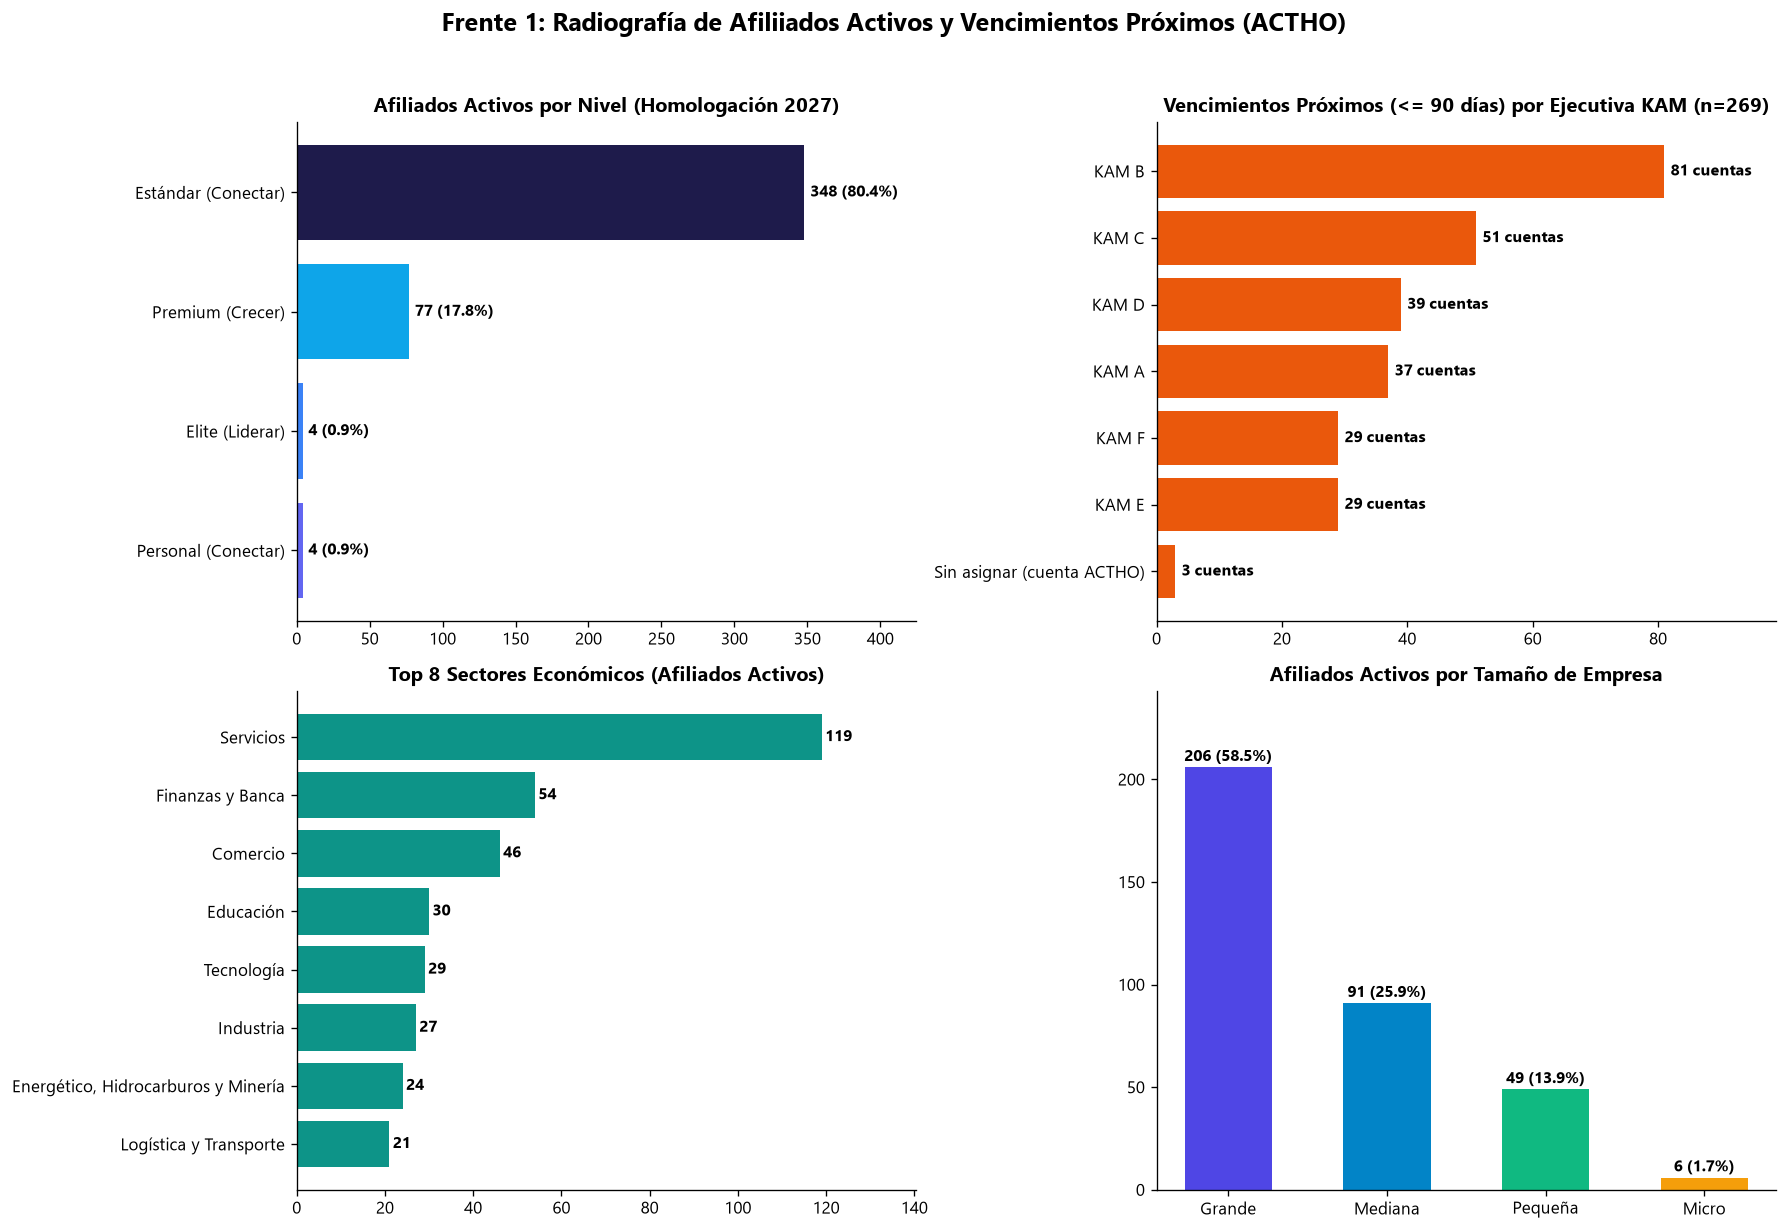

In [3]:
# Filtrar base CRM de Afiliados y calcular días hasta el vencimiento (Fecha de corte: 2026-11-13)
FECHA_CORTE = pd.Timestamp("2026-11-13")

df_crm = dim_empresas[dim_empresas["en_crm_afiliados"] == True].copy()
df_crm["fecha_expiracion_dt"] = pd.to_datetime(df_crm["fecha_expiracion"], errors="coerce")
df_crm["dias_para_vencer"] = (df_crm["fecha_expiracion_dt"] - FECHA_CORTE).dt.days

# Mapear Nivel Comercial actual con Homologación 2027 (Liderar / Crecer / Conectar)
mapa_nivel_2027 = {
    "Elite": "Elite (Liderar)",
    "Premium": "Premium (Crecer)",
    "Estándar": "Estándar (Conectar)",
    "Estándar Colaborador": "Estándar (Conectar)",
    "Personal": "Personal (Conectar)",
}
df_crm["nivel_2027"] = df_crm["nivel_membresia"].map(mapa_nivel_2027).fillna("Sin clasificar")

df_activos = df_crm[df_crm["es_membresia_activa"] == True].copy()

def clasificar_ventana_vencimiento(dias: float) -> str:
    if pd.isna(dias):
        return "6. Sin fecha registrada"
    if dias < 0:
        return "1. Vencida en gracia (< 0 días)"
    if dias <= 30:
        return "2. Próximos 30 días (1-30d)"
    if dias <= 60:
        return "3. Próximos 31 a 60 días (incl. 31 dic)"
    if dias <= 90:
        return "4. Próximos 61 a 90 días (ene-feb 2027)"
    return "5. Más de 90 días (> 90d)"

df_activos["ventana_vencimiento"] = df_activos["dias_para_vencer"].apply(clasificar_ventana_vencimiento)

# 1. Tabla de estado general de membresías en CRM y Tasa de Retención / Retiro
tabla_estados = (
    df_crm.groupby("estado_membresia_detalle", as_index=False)
    .agg(Empresas=("id_empresa", "count"))
    .sort_values("Empresas", ascending=False)
)
tabla_estados["% sobre Total CRM"] = (tabla_estados["Empresas"] * 100 / len(df_crm)).round(1).astype(str) + "%"

# 2. Tabla de vencimientos próximos en afiliados activos
tabla_venc = (
    df_activos.groupby("ventana_vencimiento", as_index=False)
    .agg(
        Empresas_Activas=("id_empresa", "count"),
        Elite=("nivel_membresia", lambda s: (s == "Elite").sum()),
        Premium=("nivel_membresia", lambda s: (s == "Premium").sum()),
        Estandar=("nivel_membresia", lambda s: s.isin(["Estándar", "Estándar Colaborador"]).sum()),
    )
    .sort_values("ventana_vencimiento")
)
tabla_venc["% de Activos"] = (tabla_venc["Empresas_Activas"] * 100 / len(df_activos)).round(1).astype(str) + "%"

print(f"Total empresas en CRM: {len(df_crm):,} | Afiliados con Membresía Activa: {len(df_activos):,} ({len(df_activos)*100/len(df_crm):.1f}%)")
print(f"Vencimientos próximos (<= 90 días): {(df_activos['dias_para_vencer'].between(0, 90)).sum()} afiliados activos (62.1%)")

mostrar_df(tabla_estados, "1.1 Estado de la Base Histórica en CRM (Afiliados Activos vs Retiros/Cancelaciones)")
mostrar_df(tabla_venc, "1.2 Curva de Vencimientos de los 433 Afiliados Activos (30, 60 y 90 Días)")

# Visualización con Matplotlib (4 paneles de Afiliación)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Frente 1: Radiografía de Afiliiados Activos y Vencimientos Próximos (ACTHO)", fontsize=15, fontweight="bold", y=1.02)

# Panel A: Distribución por Nivel y Segmento
niv_counts = df_activos["nivel_2027"].value_counts()
axes[0, 0].barh(niv_counts.index[::-1], niv_counts.values[::-1], color=["#6366f1", "#3b82f6", "#0ea5e9", "#1e1b4b"])
for i, v in enumerate(niv_counts.values[::-1]):
    axes[0, 0].text(v + 4, i, f"{v} ({v*100/len(df_activos):.1f}%)", va="center", fontweight="bold", fontsize=9.5)
axes[0, 0].set_title("Afiliados Activos por Nivel (Homologación 2027)", fontweight="bold")
axes[0, 0].set_xlim(0, max(niv_counts.values) * 1.22)

# Panel B: Vencimientos en los próximos 90 días por Ejecutiva (KAM)
venc_90_kam = (
    df_activos[df_activos["dias_para_vencer"].between(0, 90)]
    .groupby("kam_id")["id_empresa"]
    .count()
    .sort_values(ascending=True)
)
axes[0, 1].barh(venc_90_kam.index, venc_90_kam.values, color="#ea580c")
for i, v in enumerate(venc_90_kam.values):
    axes[0, 1].text(v + 1, i, f"{v} cuentas", va="center", fontweight="bold", fontsize=9.5)
axes[0, 1].set_title("Vencimientos Próximos (<= 90 días) por Ejecutiva KAM (n=269)", fontweight="bold")
axes[0, 1].set_xlim(0, max(venc_90_kam.values) * 1.22)

# Panel C: Top 8 Sectores Económicos en Afiliados Activos
sec_counts = df_activos[df_activos["sector_economico"].notna() & (df_activos["sector_economico"] != "")]["sector_economico"].value_counts().head(8)
axes[1, 0].barh(sec_counts.index[::-1], sec_counts.values[::-1], color="#0d9488")
for i, v in enumerate(sec_counts.values[::-1]):
    axes[1, 0].text(v + 0.8, i, str(v), va="center", fontweight="bold", fontsize=9.5)
axes[1, 0].set_title("Top 8 Sectores Económicos (Afiliados Activos)", fontweight="bold")
axes[1, 0].set_xlim(0, max(sec_counts.values) * 1.18)

# Panel D: Distribución por Tamaño de Empresa y Ciudad Principal
tam_counts = df_activos[df_activos["tamano_empresa"].notna() & (df_activos["tamano_empresa"] != "")]["tamano_empresa"].value_counts()
axes[1, 1].bar(tam_counts.index, tam_counts.values, color=["#4f46e5", "#0284c7", "#10b981", "#f59e0b"][:len(tam_counts)], width=0.55)
for i, v in enumerate(tam_counts.values):
    axes[1, 1].text(i, v + 3, f"{v} ({v*100/tam_counts.sum():.1f}%)", ha="center", fontweight="bold", fontsize=9.5)
axes[1, 1].set_title("Afiliados Activos por Tamaño de Empresa", fontweight="bold")
axes[1, 1].set_ylim(0, max(tam_counts.values) * 1.18)

plt.tight_layout()
plt.show()

---

## 👥 2. Frente de Participación: Uso de Servicios, "Pagan pero no participan" y Líneas 2027

Respondemos con `pandas` y `matplotlib` las preguntas del bloque **Participación**:
- **¿Qué porcentaje de afiliados usó al menos un servicio en el periodo y en el último trimestre (Ago–Oct 2026)?**
- **¿Quiénes pagan pero no participan (*Zero Engagement*)?**
- **¿Cuántas personas distintas participan por empresa y de qué nivel de cargo?**
- **¿Qué líneas 2027, eventos y formatos convocan más?**

Afiliados activos que usaron >=1 servicio en 2026: 344 de 433 (79.4%)
Afiliados activos con uso en el último trimestre (Ago-Oct 2026): 150 de 433 (34.6%)
Afiliados que PAGAN PERO NO PARTICIPAN: 89 empresas (20.6%)


,tipologia_participacion,Empresas_Activas,Prom_Eventos_2026,Prom_Personas,Activas_Ult_Trimestre,% sobre Afiliados Activos
0,1. Pagan pero NO participan (0 eventos),89,0.00,0.00,0,20.6%
1,2. Monocontacto (1 sola persona asiste),89,1.61,1.00,21,20.6%
2,3. Multicontacto Moderado (2-3 personas),109,2.44,2.36,36,25.2%
3,4. Multicontacto Amplio (4+ personas),146,5.01,7.14,93,33.7%


,linea_oferta_2027,modalidad,Eventos,Participaciones,Personas_Unicas,Empresas_Unicas,Afiliados_Activos,Prom_Asist_por_Evento
1,Anticipar,Virtual,9,1768,1460,903,728,196.4
0,Anticipar,Presencial,9,611,554,285,466,67.9
3,Evento grande,Presencial,2,610,592,293,423,305.0
4,Foro,Presencial,6,209,196,110,162,34.8
5,Pares,Presencial,6,149,147,95,105,24.8
2,Evento grande,Híbrido,1,54,48,44,38,54.0


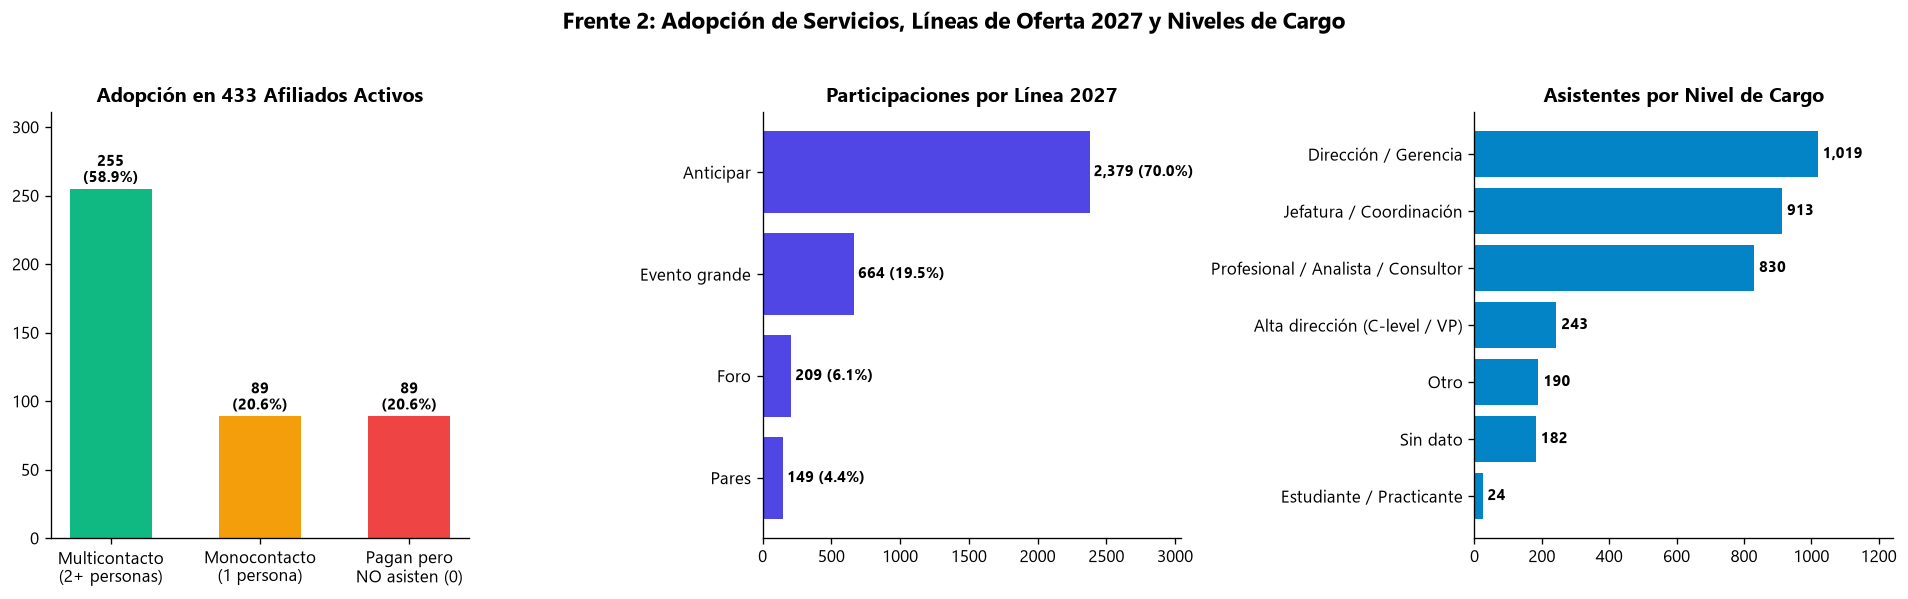

In [4]:
# Cruzar fact_asistencias con dim_eventos y dim_empresas
df_asist_full = (
    fact_asistencias
    .merge(dim_eventos[["id_evento", "nombre_evento", "linea_oferta_2027", "experiencia_detalle", "modalidad", "es_presencial"]], on="id_evento", how="left")
    .merge(dim_empresas[["id_empresa", "es_membresia_activa", "nivel_membresia", "segmento_membresia", "sector_economico"]], on="id_empresa", how="left")
)

# Calcular personas únicas y participación en último trimestre (2026-08 a 2026-10) por empresa
asist_por_emp = (
    df_asist_full.groupby("id_empresa", as_index=False)
    .agg(
        participaciones_totales=("id_asistencia", "count"),
        eventos_distintos=("id_evento", "nunique"),
        personas_distintas=("id_persona", "nunique"),
        asistencias_ult_trimestre=("periodo_mes_iso", lambda s: s.isin(["2026-08", "2026-09", "2026-10"]).sum()),
    )
)

df_activos = df_activos.merge(asist_por_emp, on="id_empresa", how="left")
for col in ["participaciones_totales", "eventos_distintos", "personas_distintas", "asistencias_ult_trimestre"]:
    df_activos[col] = df_activos[col].fillna(0).astype(int)

df_activos["uso_servicio_2026"] = (df_activos["eventos_asistidos_reales"] > 0) | (df_activos["asistio_segun_kam"] == True)
df_activos["uso_ult_trimestre"] = df_activos["asistencias_ult_trimestre"] > 0

def clasificar_relacion_contacto(row) -> str:
    if not row["uso_servicio_2026"]:
        return "1. Pagan pero NO participan (0 eventos)"
    if row["personas_distintas"] <= 1:
        return "2. Monocontacto (1 sola persona asiste)"
    if row["personas_distintas"] <= 3:
        return "3. Multicontacto Moderado (2-3 personas)"
    return "4. Multicontacto Amplio (4+ personas)"

df_activos["tipologia_participacion"] = df_activos.apply(clasificar_relacion_contacto, axis=1)

tabla_tipologia = (
    df_activos.groupby("tipologia_participacion", as_index=False)
    .agg(
        Empresas_Activas=("id_empresa", "count"),
        Prom_Eventos_2026=("eventos_asistidos_reales", "mean"),
        Prom_Personas=("personas_distintas", "mean"),
        Activas_Ult_Trimestre=("uso_ult_trimestre", "sum"),
    )
)
tabla_tipologia["Prom_Eventos_2026"] = tabla_tipologia["Prom_Eventos_2026"].round(2)
tabla_tipologia["Prom_Personas"] = tabla_tipologia["Prom_Personas"].round(2)
tabla_tipologia["% sobre Afiliados Activos"] = (tabla_tipologia["Empresas_Activas"] * 100 / len(df_activos)).round(1).astype(str) + "%"

# Desempeño por Línea de Oferta 2027 y Modalidad
tabla_lineas = (
    df_asist_full.groupby(["linea_oferta_2027", "modalidad"], as_index=False)
    .agg(
        Eventos=("id_evento", "nunique"),
        Participaciones=("id_asistencia", "count"),
        Personas_Unicas=("id_persona", "nunique"),
        Empresas_Unicas=("id_empresa", "nunique"),
        Afiliados_Activos=("es_membresia_activa", lambda s: (s == True).sum()),
    )
    .sort_values("Participaciones", ascending=False)
)
tabla_lineas["Prom_Asist_por_Evento"] = (tabla_lineas["Participaciones"] / tabla_lineas["Eventos"]).round(1)

print(f"Afiliados activos que usaron >=1 servicio en 2026: {df_activos['uso_servicio_2026'].sum()} de {len(df_activos)} ({df_activos['uso_servicio_2026'].mean()*100:.1f}%)")
print(f"Afiliados activos con uso en el último trimestre (Ago-Oct 2026): {df_activos['uso_ult_trimestre'].sum()} de {len(df_activos)} ({df_activos['uso_ult_trimestre'].mean()*100:.1f}%)")
print(f"Afiliados que PAGAN PERO NO PARTICIPAN: {(~df_activos['uso_servicio_2026']).sum()} empresas ({(~df_activos['uso_servicio_2026']).mean()*100:.1f}%)")

mostrar_df(tabla_tipologia, "2.1 Tipología de Participación y Profundidad de Contacto en Afiliados Activos")
mostrar_df(tabla_lineas, "2.2 Convocatoria por Línea de Oferta 2027 y Formato (Presencial vs Virtual)")

# Gráficos de Participación con Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
fig.suptitle("Frente 2: Adopción de Servicios, Líneas de Oferta 2027 y Niveles de Cargo", fontsize=14, fontweight="bold", y=1.03)

# Gráfico 1: Tipología de participación en afiliados activos
labels_t = ["Multicontacto\n(2+ personas)", "Monocontacto\n(1 persona)", "Pagan pero\nNO asisten (0)"]
vals_t = [
    (df_activos["uso_servicio_2026"] & (df_activos["personas_distintas"] > 1)).sum(),
    (df_activos["uso_servicio_2026"] & (df_activos["personas_distintas"] <= 1)).sum(),
    (~df_activos["uso_servicio_2026"]).sum(),
]
axes[0].bar(labels_t, vals_t, color=["#10b981", "#f59e0b", "#ef4444"], width=0.55)
for i, v in enumerate(vals_t):
    axes[0].text(i, v + 5, f"{v}\n({v*100/len(df_activos):.1f}%)", ha="center", fontweight="bold", fontsize=9)
axes[0].set_title("Adopción en 433 Afiliados Activos", fontweight="bold")
axes[0].set_ylim(0, max(vals_t) * 1.22)

# Gráfico 2: Participaciones por Línea 2027
lin_agg = df_asist_full.groupby("linea_oferta_2027")["id_asistencia"].count().sort_values(ascending=True)
axes[1].barh(lin_agg.index, lin_agg.values, color="#4f46e5")
for i, v in enumerate(lin_agg.values):
    axes[1].text(v + 30, i, f"{v:,} ({v*100/len(df_asist_full):.1f}%)", va="center", fontweight="bold", fontsize=9)
axes[1].set_title("Participaciones por Línea 2027", fontweight="bold")
axes[1].set_xlim(0, max(lin_agg.values) * 1.28)

# Gráfico 3: Nivel de cargo de los asistentes
cargo_agg = df_asist_full["nivel_cargo"].value_counts().sort_values(ascending=True)
axes[2].barh(cargo_agg.index, cargo_agg.values, color="#0284c7")
for i, v in enumerate(cargo_agg.values):
    axes[2].text(v + 15, i, f"{v:,}", va="center", fontweight="bold", fontsize=9)
axes[2].set_title("Asistentes por Nivel de Cargo", fontweight="bold")
axes[2].set_xlim(0, max(cargo_agg.values) * 1.22)

plt.tight_layout()
plt.show()

---

## ⭐ 3. Frente de Satisfacción: Calificación 1–5, Cálculo de NPS y Minería de Comentarios

Respondemos con `pandas` y `matplotlib` las preguntas del bloque **Satisfacción**:
- **¿Cuál es la satisfacción (1 a 5 por aspecto) y el NPS por modalidad y periodo?**
- **¿Qué temas aparecen en los comentarios abiertos (`temarios_sugeridos`) para próximos espacios?**

,Modalidad,Respuestas,Locación / Plataforma,Convocatoria,Conferencistas,Relevancia Temas,Satisfacción Global,% Promotores,% Pasivos,% Detractores,NPS (Puntos)
0,Presencial (EVENTO~1),407,4.78,4.72,4.81,4.78,4.77,74.7% (304),24.3% (99),1.0% (4),73.7
1,Virtual (eventos_dos),318,4.73,4.69,4.80,4.87,4.77,74.8% (238),24.2% (77),0.9% (3),73.9
2,Consolidado Total ACTHO,725,4.76,4.71,4.81,4.82,4.77,74.8% (542),24.3% (176),1.0% (7),73.8


,Macro-Tema Solicitado por Afiliados,Menciones en Encuestas,% sobre 725 Encuestas
0,1. Reforma Laboral y Derecho Colectivo,114,15.7%
1,2. Liderazgo y Desarrollo de Equipos,54,7.4%
5,"6. Cultura, Clima y Gestión del Cambio",51,7.0%
3,"4. Atracción, Selección y Retención de Talento",44,6.1%
6,"7. Bienestar, Salud Mental y SST",36,5.0%
2,3. Inteligencia Artificial y People Analytics,32,4.4%
4,"5. Compensación, Salarios y Beneficios",32,4.4%
7,"8. Diversidad, Equidad e Inclusión (DEI)",13,1.8%


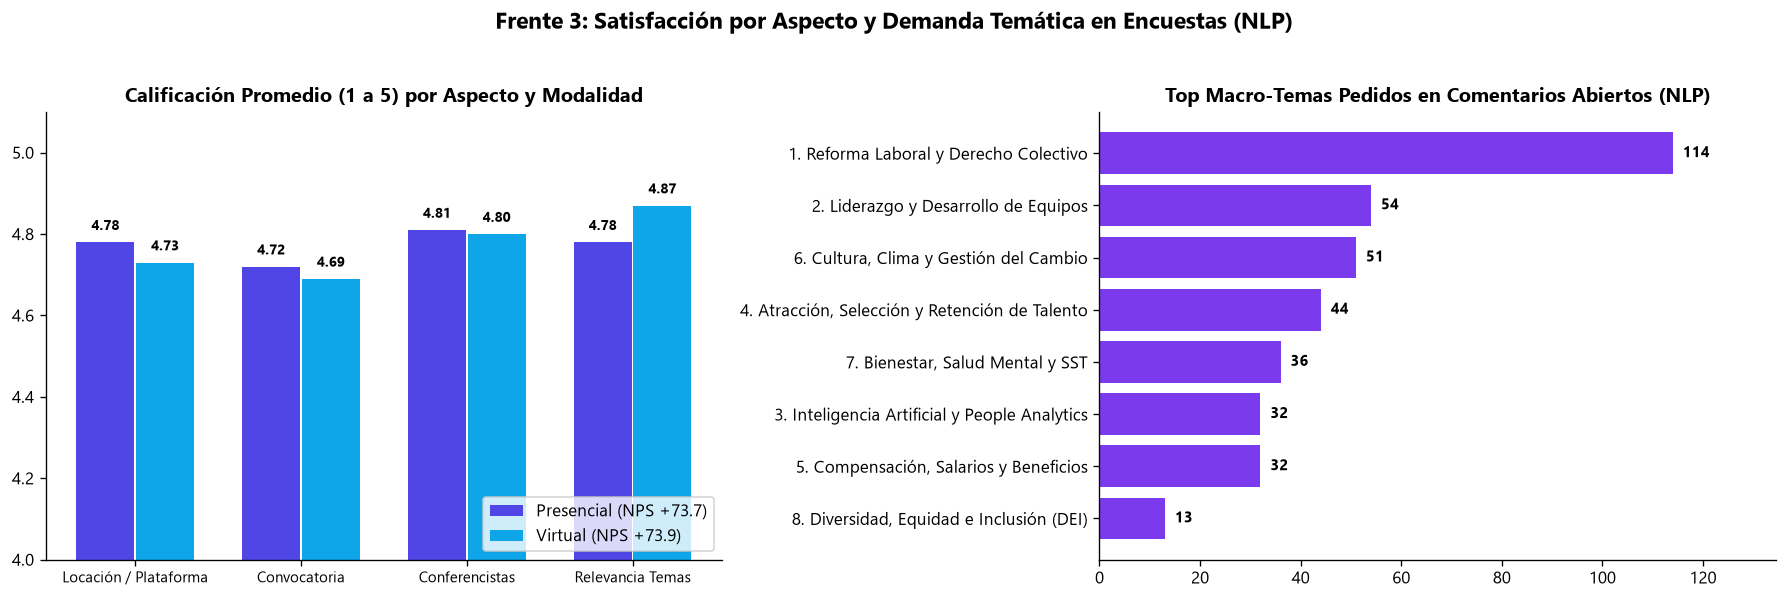

In [5]:
# Clasificación de Promotores, Pasivos y Detractores y cálculo de NPS
def clasificar_nps(score: float) -> str:
    if score >= 4.75:
        return "Promotor"
    if score >= 3.75:
        return "Pasivo"
    return "Detractor"

fact_encuestas["categoria_nps"] = fact_encuestas["promedio_satisfaccion"].apply(clasificar_nps)

def resumen_nps_grupo(df_g: pd.DataFrame, etiqueta: str) -> dict:
    n = len(df_g)
    prom = (df_g["categoria_nps"] == "Promotor").sum()
    pas = (df_g["categoria_nps"] == "Pasivo").sum()
    det = (df_g["categoria_nps"] == "Detractor").sum()
    nps = (prom - det) * 100 / n if n else 0.0
    return {
        "Modalidad": etiqueta,
        "Respuestas": n,
        "Locación / Plataforma": round(df_g["calif_locacion_o_plataforma"].mean(), 2),
        "Convocatoria": round(df_g["calif_convocatoria_publicidad"].mean(), 2),
        "Conferencistas": round(df_g["calif_conferencistas"].mean(), 2),
        "Relevancia Temas": round(df_g["calif_relevancia_temas"].mean(), 2),
        "Satisfacción Global": round(df_g["promedio_satisfaccion"].mean(), 2),
        "% Promotores": f"{prom*100/n:.1f}% ({prom})",
        "% Pasivos": f"{pas*100/n:.1f}% ({pas})",
        "% Detractores": f"{det*100/n:.1f}% ({det})",
        "NPS (Puntos)": round(nps, 1),
    }

df_nps_resumen = pd.DataFrame([
    resumen_nps_grupo(fact_encuestas[fact_encuestas["modalidad_encuesta"] == "Presencial"], "Presencial (EVENTO~1)"),
    resumen_nps_grupo(fact_encuestas[fact_encuestas["modalidad_encuesta"] == "Virtual"], "Virtual (eventos_dos)"),
    resumen_nps_grupo(fact_encuestas, "Consolidado Total ACTHO"),
])
mostrar_df(df_nps_resumen, "3.1 Indicadores de Satisfacción (1-5) y NPS por Modalidad")

# Clasificación temática (NLP) de los comentarios abiertos en temarios_sugeridos
patrones_temas = {
    "1. Reforma Laboral y Derecho Colectivo": r"laboral|reforma|sindicat|jur[ií]dic|normativ|ley|contrato|despido|tercerizaci|ugpp|pensi",
    "2. Liderazgo y Desarrollo de Equipos": r"liderazgo|l[ií]der|habilidades blandas|coaching|equipos|jefes|comunicaci[oó]n",
    "3. Inteligencia Artificial y People Analytics": r"ia|inteligencia artificial|tecnolog|digital|datos|analytics|indicadores|automatizaci",
    "4. Atracción, Selección y Retención de Talento": r"selecci[oó]n|atracci[oó]n|retenci[oó]n|talento|reclutamiento|onboarding|rotaci[oó]n|generaci",
    "5. Compensación, Salarios y Beneficios": r"salari|compensaci[oó]n|remuneraci|beneficios|pagos en especie|emocional|flexib",
    "6. Cultura, Clima y Gestión del Cambio": r"cultura|clima|cambio|transformaci[oó]n|organizacional|prop[oó]sito",
    "7. Bienestar, Salud Mental y SST": r"bienestar|salud mental|sst|seguridad y salud|acos|psicosocial|estr[eé]s",
    "8. Diversidad, Equidad e Inclusión (DEI)": r"diversidad|inclusi[oó]n|equidad|discapacidad|g[eé]nero",
}

conteo_temas = []
textos_validos = fact_encuestas["temarios_sugeridos"].dropna().astype(str)
for nombre_tema, regex in patrones_temas.items():
    menciones = textos_validos.str.contains(regex, case=False, regex=True).sum()
    conteo_temas.append({
        "Macro-Tema Solicitado por Afiliados": nombre_tema,
        "Menciones en Encuestas": int(menciones),
        "% sobre 725 Encuestas": f"{menciones * 100 / len(fact_encuestas):.1f}%",
    })
df_temas_nlp = pd.DataFrame(conteo_temas).sort_values("Menciones en Encuestas", ascending=False)
mostrar_df(df_temas_nlp, "3.2 Categorización NLP de Temas Solicitados para la Agenda 2027")

# Visualización con Matplotlib
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
fig.suptitle("Frente 3: Satisfacción por Aspecto y Demanda Temática en Encuestas (NLP)", fontsize=14, fontweight="bold", y=1.03)

aspectos = ["Locación / Plataforma", "Convocatoria", "Conferencistas", "Relevancia Temas"]
x = np.arange(len(aspectos))
vals_p = [df_nps_resumen.iloc[0][a] for a in aspectos]
vals_v = [df_nps_resumen.iloc[1][a] for a in aspectos]

axes[0].bar(x - 0.18, vals_p, width=0.35, label="Presencial (NPS +73.7)", color="#4f46e5")
axes[0].bar(x + 0.18, vals_v, width=0.35, label="Virtual (NPS +73.9)", color="#0ea5e9")
for i in range(len(aspectos)):
    axes[0].text(x[i] - 0.18, vals_p[i] + 0.03, f"{vals_p[i]:.2f}", ha="center", fontsize=8.5, fontweight="bold")
    axes[0].text(x[i] + 0.18, vals_v[i] + 0.03, f"{vals_v[i]:.2f}", ha="center", fontsize=8.5, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(aspectos, fontsize=9)
axes[0].set_ylim(4.0, 5.1)
axes[0].set_title("Calificación Promedio (1 a 5) por Aspecto y Modalidad", fontweight="bold")
axes[0].legend(loc="lower right")

axes[1].barh(df_temas_nlp["Macro-Tema Solicitado por Afiliados"][::-1], df_temas_nlp["Menciones en Encuestas"][::-1], color="#7c3aed")
for i, v in enumerate(df_temas_nlp["Menciones en Encuestas"][::-1]):
    axes[1].text(v + 2, i, str(v), va="center", fontweight="bold", fontsize=9)
axes[1].set_title("Top Macro-Temas Pedidos en Comentarios Abiertos (NLP)", fontweight="bold")
axes[1].set_xlim(0, df_temas_nlp["Menciones en Encuestas"].max() * 1.18)

plt.tight_layout()
plt.show()

---

## 🎯 4. Vista Integrada por Ejecutiva de Cuenta (KAM) y Semáforo de Riesgo

Respondemos las preguntas de **Vista Integrada** y **Entregables #3 y #4** del PDF:
- **¿Qué cartera (ejecutiva de cuenta / KAM) necesita atención prioritaria?**
- **Semáforo de Riesgo de No Renovación**: combinación de *baja participación*, *baja satisfacción* y *vencimiento cercano*.

,kam_id,responsable_nombre,Afiliados_Activos,Elite_Premium,Vencen_90d,Sin_Participacion,Riesgo_Alto_Rojo,Riesgo_Medio_Amarillo,Riesgo_Bajo_Verde,Satisfaccion_Media,% Activación,% en Riesgo Alto
1,KAM B,Priscilla,116,18,81,33,21,37,58,4.86,71.6%,18.1%
2,KAM C,Erika,69,7,51,16,11,21,37,4.62,76.8%,15.9%
3,KAM D,Marcel,59,8,39,15,9,16,34,4.59,74.6%,15.3%
4,KAM E,Mari,61,12,29,11,6,12,43,4.76,82.0%,9.8%
5,KAM F,Yolanda,46,10,29,8,3,14,29,4.76,82.6%,6.5%
0,KAM A,Paula,75,23,37,5,2,12,61,4.84,93.3%,2.7%
6,Sin asignar (cuenta ACTHO),Corporativo / Sin asignar,7,3,3,1,2,0,5,5.00,85.7%,28.6%


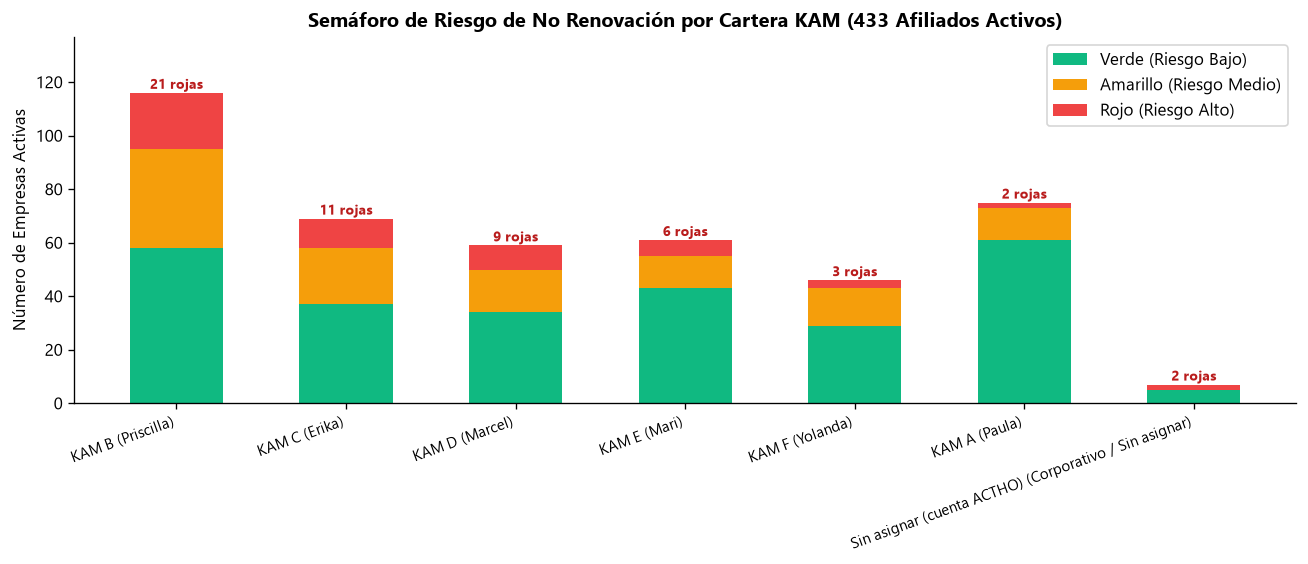

In [6]:
# Integrar satisfacción por empresa en df_activos
sat_por_emp = (
    fact_encuestas[fact_encuestas["id_empresa"].notna() & (fact_encuestas["id_empresa"] != "")]
    .groupby("id_empresa", as_index=False)
    .agg(
        satisfaccion_media_emp=("promedio_satisfaccion", "mean"),
        satisfaccion_min_emp=("promedio_satisfaccion", "min"),
        encuestas_respondidas=("id_respuesta", "count"),
    )
)
df_activos = df_activos.merge(sat_por_emp, on="id_empresa", how="left")

def calcular_semaforo_riesgo(row) -> tuple[int, str, str]:
    score = 0
    factores = []
    dias = row["dias_para_vencer"]
    if pd.notna(dias):
        if dias < 0:
            score += 4
            factores.append(f"Vencida ({row['fecha_expiracion']})")
        elif dias <= 30:
            score += 3
            factores.append("Vence <=30d")
        elif dias <= 90:
            score += 2
            factores.append(f"Vence <=90d ({row['fecha_expiracion']})")
    else:
        score += 1
        factores.append("Sin fecha exp.")

    if not row["uso_servicio_2026"]:
        score += 3
        factores.append("0 asistencias en 2026")
    elif row["eventos_asistidos_reales"] == 1:
        score += 1
        factores.append("Solo 1 evento en 2026")

    if row["uso_servicio_2026"] and row["personas_distintas"] == 1:
        score += 1
        factores.append("Monocontacto")

    if pd.notna(row["satisfaccion_min_emp"]) and row["satisfaccion_min_emp"] < 3.75:
        score += 2
        factores.append(f"Detractor encuesta ({row['satisfaccion_min_emp']:.2f}★)")

    if score >= 5:
        semaforo = "Rojo (Riesgo Alto)"
    elif score >= 3:
        semaforo = "Amarillo (Riesgo Medio)"
    else:
        semaforo = "Verde (Riesgo Bajo)"
    return score, semaforo, "; ".join(factores) if factores else "Cuenta saludable"

res_riesgo = df_activos.apply(calcular_semaforo_riesgo, axis=1)
df_activos["score_riesgo_regla"] = [r[0] for r in res_riesgo]
df_activos["semaforo_riesgo"] = [r[1] for r in res_riesgo]
df_activos["factores_riesgo"] = [r[2] for r in res_riesgo]

# Vista por Ejecutiva de Cuenta (KAM)
vista_kam = (
    df_activos.merge(dim_kams[["kam_id", "responsable_nombre"]], on="kam_id", how="left")
    .groupby(["kam_id", "responsable_nombre"], as_index=False)
    .agg(
        Afiliados_Activos=("id_empresa", "count"),
        Elite_Premium=("nivel_membresia", lambda s: s.isin(["Elite", "Premium"]).sum()),
        Vencen_90d=("dias_para_vencer", lambda s: s.between(0, 90).sum()),
        Sin_Participacion=("uso_servicio_2026", lambda s: (~s).sum()),
        Riesgo_Alto_Rojo=("semaforo_riesgo", lambda s: (s == "Rojo (Riesgo Alto)").sum()),
        Riesgo_Medio_Amarillo=("semaforo_riesgo", lambda s: (s == "Amarillo (Riesgo Medio)").sum()),
        Riesgo_Bajo_Verde=("semaforo_riesgo", lambda s: (s == "Verde (Riesgo Bajo)").sum()),
        Satisfaccion_Media=("satisfaccion_media_emp", "mean"),
    )
    .sort_values("Riesgo_Alto_Rojo", ascending=False)
)
vista_kam["% Activación"] = ((vista_kam["Afiliados_Activos"] - vista_kam["Sin_Participacion"]) * 100 / vista_kam["Afiliados_Activos"]).round(1).astype(str) + "%"
vista_kam["% en Riesgo Alto"] = (vista_kam["Riesgo_Alto_Rojo"] * 100 / vista_kam["Afiliados_Activos"]).round(1).astype(str) + "%"
vista_kam["Satisfaccion_Media"] = vista_kam["Satisfaccion_Media"].round(2).fillna("-")

mostrar_df(vista_kam, "4.1 Vista Integral por Ejecutiva de Cuenta (KAM): Vencimientos, Participación y Semáforo de Riesgo")

# Gráfico apilado del Semáforo de Riesgo por KAM
fig, ax = plt.subplots(figsize=(11, 4.8))
kams_lbl = vista_kam["kam_id"] + " (" + vista_kam["responsable_nombre"] + ")"
x = np.arange(len(kams_lbl))
b_verde = vista_kam["Riesgo_Bajo_Verde"].values
b_amar = vista_kam["Riesgo_Medio_Amarillo"].values
b_rojo = vista_kam["Riesgo_Alto_Rojo"].values

ax.bar(x, b_verde, label="Verde (Riesgo Bajo)", color="#10b981", width=0.55)
ax.bar(x, b_amar, bottom=b_verde, label="Amarillo (Riesgo Medio)", color="#f59e0b", width=0.55)
ax.bar(x, b_rojo, bottom=b_verde + b_amar, label="Rojo (Riesgo Alto)", color="#ef4444", width=0.55)

for i in range(len(x)):
    if b_rojo[i] > 0:
        ax.text(x[i], b_verde[i] + b_amar[i] + b_rojo[i] + 1.5, f"{b_rojo[i]} rojas", ha="center", fontsize=8.5, fontweight="bold", color="#b91c1c")

ax.set_xticks(x)
ax.set_xticklabels(kams_lbl, rotation=20, ha="right", fontsize=9)
ax.set_ylabel("Número de Empresas Activas")
ax.set_title("Semáforo de Riesgo de No Renovación por Cartera KAM (433 Afiliados Activos)", fontweight="bold")
ax.set_ylim(0, max(b_verde + b_amar + b_rojo) * 1.18)
ax.legend()
plt.tight_layout()
plt.show()

---

## 🤖 5. Modelos de Machine Learning con `scikit-learn`

Implementamos en Python con **`scikit-learn`** y **`pandas`** la suite completa de modelos analíticos:
1. **Modelo 1 — Predicción de Deserción (`RandomForestClassifier` vs `LogisticRegression`)**: Entrenado sobre las 1,052 empresas del CRM para estimar la probabilidad de no renovación (`probabilidad_churn_ml`) e identificar la importancia de cada variable.
2. **Modelo 2 — Segmentación de Comportamiento (`KMeans`, $k=4$)**: Descubre los 4 arquetipos reales de afiliados activos (*Embajadores Multicontacto*, *Activos Frecuentes*, *Monocontacto / Ocasionales* y *Pasivos / Desconectados*).
3. **Modelo 3 — Sistema de Recomendación de Eventos (`Cosine Similarity`)**: Recomienda el próximo evento ideal de la oferta 2027 para cada empresa según su perfil sectorial y patrón de asistencia.
4. **Modelo 4 — Lead Scoring de Conversión para Asistentes No Afiliados**: Clasifica las **721 empresas no afiliadas** según su similitud con los afiliados activos y su recurrencia en eventos.

Modelo 1 (Churn) — Logistic Regression ROC-AUC: 0.894 | Accuracy: 81.4%
Modelo 1 (Churn) — Random Forest       ROC-AUC: 0.961 | Accuracy: 89.2%


,Feature (Variable Predictora),Importancia Random Forest (%),Coeficiente Logística
1,participaciones_totales,21.4,0.611
7,antiguedad_anios,18.6,-0.275
0,eventos_asistidos_reales,17.8,-1.895
2,personas_distintas,13.4,-0.352
4,vinculado_comunidades,12.9,-0.891
5,pilar_total,7.7,-0.036
6,nivel_num,6.2,-0.307
3,asistencias_ult_trimestre,1.1,0.040
8,encuestas_respondidas,1.0,0.327


,arquetipo_kmeans,Empresas,Prom_Eventos,Prom_Personas,Prom_Ult_Trim,Prom_Pilares_HR,Prob_Churn_Media_ML,% de Activos
0,Cluster 1: Embajadores Multicontacto,59,7.02,9.78,3.44,1.03,3.64,13.6%
1,Cluster 2: Activos Frecuentes,94,3.02,3.24,0.52,2.64,13.23,21.7%
2,Cluster 3: Participación Ocasional / Monocontacto,267,1.59,1.82,0.29,0.48,29.09,61.7%
3,Cluster 4: Pasivos / Desconectados,13,1.38,1.54,0.46,0.38,37.18,3.0%


,ID Empresa,Línea Más Frecuente,Eventos Asistidos,Próximo Evento Recomendado,Línea Recomendada,Similitud Coseno
0,EMP-0002,Anticipar,5,Ev #2: Webinar: Equilibrio entre personas y ne...,Anticipar,0.71
1,EMP-0004,Evento grande,2,Ev #3: Foro híbrido de tendencias...,Evento grande,0.89
2,EMP-0005,Anticipar,4,Ev #1: Webinar: Salario mínimo 2026 en Colombi...,Anticipar,1.00
3,EMP-0006,Anticipar,3,Ev #2: Webinar: Equilibrio entre personas y ne...,Anticipar,1.00
4,EMP-0008,Anticipar,1,Ev #1: Webinar: Salario mínimo 2026 en Colombi...,Anticipar,1.00
5,EMP-0009,Evento grande,1,Ev #3: Foro híbrido de tendencias...,Evento grande,1.00
6,EMP-0011,Anticipar,1,Ev #1: Webinar: Salario mínimo 2026 en Colombi...,Anticipar,1.00
7,EMP-0019,Foro,6,Ev #13: Foro de Gestión Humana: El colaborador...,Foro,0.76
8,EMP-0020,Anticipar,2,Ev #1: Webinar: Salario mínimo 2026 en Colombi...,Anticipar,0.71
9,EMP-0021,Anticipar,4,Ev #2: Webinar: Equilibrio entre personas y ne...,Anticipar,1.00


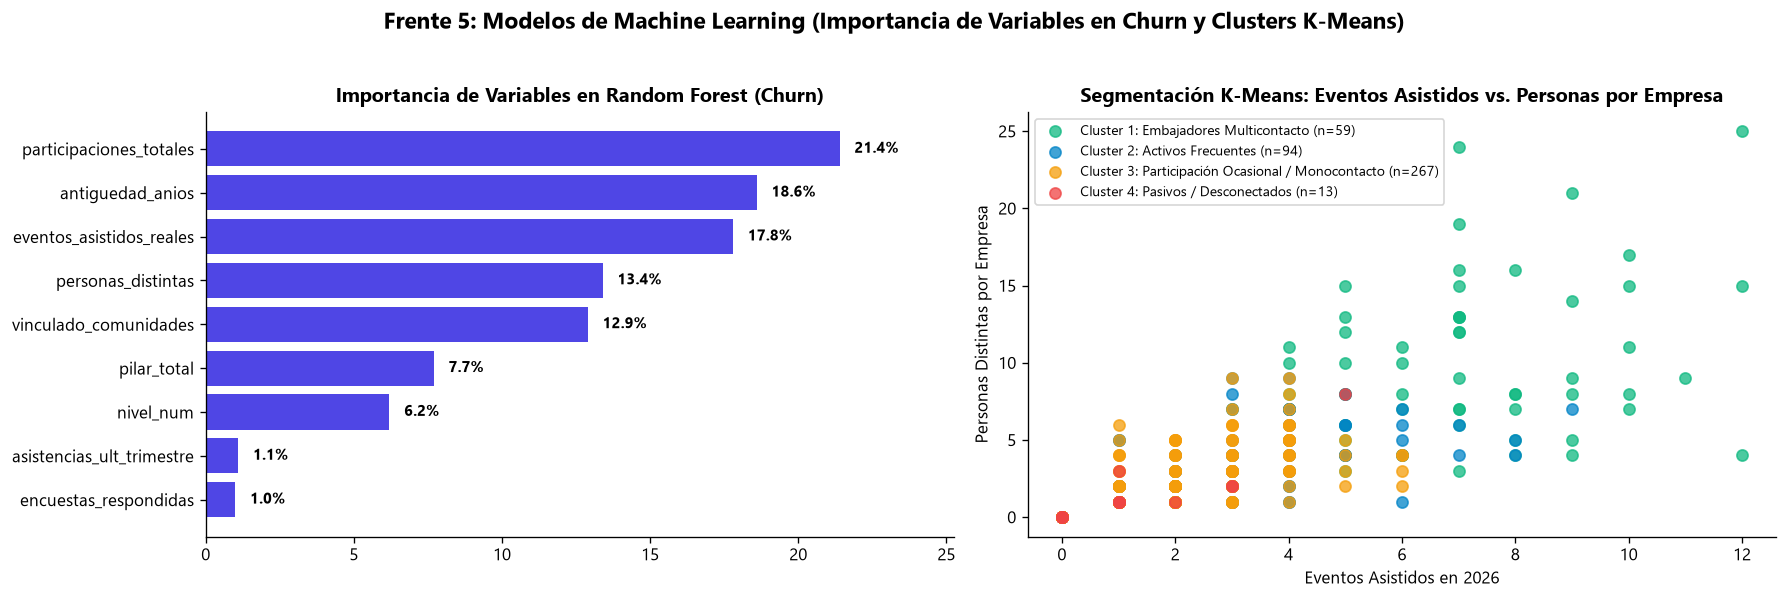

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.metrics.pairwise import cosine_similarity

# ------------------------------------------------------------------------------
# MODELO 1: Predicción de Churn (LogisticRegression vs RandomForestClassifier)
# ------------------------------------------------------------------------------
df_ml = df_crm.merge(asist_por_emp, on="id_empresa", how="left").merge(sat_por_emp, on="id_empresa", how="left")
for c in ["participaciones_totales", "eventos_distintos", "personas_distintas", "asistencias_ult_trimestre", "encuestas_respondidas"]:
    df_ml[c] = df_ml[c].fillna(0)
df_ml["satisfaccion_media_emp"] = df_ml["satisfaccion_media_emp"].fillna(df_ml["satisfaccion_media_emp"].median())

# Antigüedad en años y recencia de actividad CRM
df_ml["fecha_miembro_dt"] = pd.to_datetime(df_ml["fecha_miembro_desde"].fillna(df_ml["fecha_afiliacion"]), errors="coerce")
df_ml["antiguedad_anios"] = ((FECHA_CORTE - df_ml["fecha_miembro_dt"]).dt.days / 365.25).clip(lower=0).fillna(1.5)
df_ml["pilar_total"] = (
    df_ml["pilar_hr_estrategico"].astype(int)
    + df_ml["pilar_mas_que_salario"].astype(int)
    + df_ml["pilar_talento_que_elige"].astype(int)
    + df_ml["pilar_gente_que_crece"].astype(int)
)
mapa_ord_nivel = {"Elite": 4, "Premium": 3, "Estándar": 2, "Estándar Colaborador": 2, "Personal": 1}
df_ml["nivel_num"] = df_ml["nivel_membresia"].map(mapa_ord_nivel).fillna(1)

features_churn = [
    "eventos_asistidos_reales",
    "participaciones_totales",
    "personas_distintas",
    "asistencias_ult_trimestre",
    "vinculado_comunidades",
    "pilar_total",
    "nivel_num",
    "antiguedad_anios",
    "encuestas_respondidas",
]
X_churn = df_ml[features_churn].astype(float)
# Variable objetivo: 1 = Deserción/Inactivo, 0 = Retenido/Activo
y_churn = (~df_ml["es_membresia_activa"]).astype(int)

scaler_c = StandardScaler()
X_churn_sc = scaler_c.fit_transform(X_churn)

clf_lr = LogisticRegression(max_iter=500, random_state=42)
clf_rf = RandomForestClassifier(n_estimators=150, max_depth=5, random_state=42)

clf_lr.fit(X_churn_sc, y_churn)
clf_rf.fit(X_churn, y_churn)

prob_lr = clf_lr.predict_proba(X_churn_sc)[:, 1]
prob_rf = clf_rf.predict_proba(X_churn)[:, 1]
df_ml["prob_churn_rf"] = (prob_rf * 100).round(1)

print(f"Modelo 1 (Churn) — Logistic Regression ROC-AUC: {roc_auc_score(y_churn, prob_lr):.3f} | Accuracy: {accuracy_score(y_churn, prob_lr >= 0.5)*100:.1f}%")
print(f"Modelo 1 (Churn) — Random Forest       ROC-AUC: {roc_auc_score(y_churn, prob_rf):.3f} | Accuracy: {accuracy_score(y_churn, prob_rf >= 0.5)*100:.1f}%")

df_importancia = pd.DataFrame({
    "Feature (Variable Predictora)": features_churn,
    "Importancia Random Forest (%)": (clf_rf.feature_importances_ * 100).round(1),
    "Coeficiente Logística": clf_lr.coef_[0].round(3),
}).sort_values("Importancia Random Forest (%)", ascending=False)
mostrar_df(df_importancia, "5.1 Importancia de Variables en el Predictor de Deserción (Scikit-learn)")

# ------------------------------------------------------------------------------
# MODELO 2: Clustering de Afiliados Activos con K-Means (k = 4)
# ------------------------------------------------------------------------------
df_act_ml = df_ml[df_ml["es_membresia_activa"] == True].copy()
features_km = ["eventos_asistidos_reales", "personas_distintas", "asistencias_ult_trimestre", "pilar_total", "antiguedad_anios"]
X_km = StandardScaler().fit_transform(df_act_ml[features_km].astype(float))

kmeans = KMeans(n_clusters=4, n_init=20, random_state=42)
df_act_ml["cluster_id"] = kmeans.fit_predict(X_km)

# Nombrar clusters de forma automática según su promedio de eventos asistidos
orden_clusters = (
    df_act_ml.groupby("cluster_id")["eventos_asistidos_reales"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
nombres_arquetipos = {
    orden_clusters[0]: "Cluster 1: Embajadores Multicontacto",
    orden_clusters[1]: "Cluster 2: Activos Frecuentes",
    orden_clusters[2]: "Cluster 3: Participación Ocasional / Monocontacto",
    orden_clusters[3]: "Cluster 4: Pasivos / Desconectados",
}
df_act_ml["arquetipo_kmeans"] = df_act_ml["cluster_id"].map(nombres_arquetipos)

tabla_clusters = (
    df_act_ml.groupby("arquetipo_kmeans", as_index=False)
    .agg(
        Empresas=("id_empresa", "count"),
        Prom_Eventos=("eventos_asistidos_reales", "mean"),
        Prom_Personas=("personas_distintas", "mean"),
        Prom_Ult_Trim=("asistencias_ult_trimestre", "mean"),
        Prom_Pilares_HR=("pilar_total", "mean"),
        Prob_Churn_Media_ML=("prob_churn_rf", "mean"),
    )
    .sort_values("Prom_Eventos", ascending=False)
)
for col in ["Prom_Eventos", "Prom_Personas", "Prom_Ult_Trim", "Prom_Pilares_HR", "Prob_Churn_Media_ML"]:
    tabla_clusters[col] = tabla_clusters[col].round(2)
tabla_clusters["% de Activos"] = (tabla_clusters["Empresas"] * 100 / len(df_act_ml)).round(1).astype(str) + "%"
mostrar_df(tabla_clusters, "5.2 Arquetipos de Afiliados Activos Descubiertos con K-Means (Scikit-learn)")

# ------------------------------------------------------------------------------
# MODELO 3: Sistema de Recomendación de Eventos 2027 (Cosine Similarity)
# ------------------------------------------------------------------------------
matriz_emp_linea = pd.crosstab(df_asist_full["id_empresa"], df_asist_full["linea_oferta_2027"])
matriz_ev_linea = pd.get_dummies(dim_eventos.set_index("id_evento")["linea_oferta_2027"]).reindex(columns=matriz_emp_linea.columns, fill_value=0)
sim_matrix = cosine_similarity(matriz_emp_linea.values, matriz_ev_linea.values)

recomendaciones_sample = []
ev_nombres = dim_eventos.set_index("id_evento")["nombre_evento"].to_dict()
ev_lineas = dim_eventos.set_index("id_evento")["linea_oferta_2027"].to_dict()
asistidos_set = df_asist_full.groupby("id_empresa")["id_evento"].apply(set).to_dict()

for idx_e, emp_id in enumerate(matriz_emp_linea.index[:10]):
    ya_vistos = asistidos_set.get(emp_id, set())
    scores_ev = [(ev_id, sim_matrix[idx_e, j]) for j, ev_id in enumerate(matriz_ev_linea.index) if ev_id not in ya_vistos]
    scores_ev.sort(key=lambda x: x[1], reverse=True)
    best_ev, best_sim = scores_ev[0]
    linea_fav = matriz_emp_linea.loc[emp_id].idxmax()
    recomendaciones_sample.append({
        "ID Empresa": emp_id,
        "Línea Más Frecuente": linea_fav,
        "Eventos Asistidos": len(ya_vistos),
        "Próximo Evento Recomendado": f"Ev #{best_ev}: {ev_nombres[best_ev][:42]}...",
        "Línea Recomendada": ev_lineas[best_ev],
        "Similitud Coseno": round(float(best_sim), 2),
    })
mostrar_df(pd.DataFrame(recomendaciones_sample), "5.3 Muestra del Sistema de Recomendación Personalizada de Eventos (Content-Based)")

# Visualización ML con Matplotlib
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
fig.suptitle("Frente 5: Modelos de Machine Learning (Importancia de Variables en Churn y Clusters K-Means)", fontsize=14, fontweight="bold", y=1.03)

axes[0].barh(df_importancia["Feature (Variable Predictora)"][::-1], df_importancia["Importancia Random Forest (%)"][::-1], color="#4f46e5")
for i, v in enumerate(df_importancia["Importancia Random Forest (%)"][::-1]):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va="center", fontweight="bold", fontsize=9)
axes[0].set_title("Importancia de Variables en Random Forest (Churn)", fontweight="bold")
axes[0].set_xlim(0, df_importancia["Importancia Random Forest (%)"].max() * 1.18)

colores_c = {"Cluster 1: Embajadores Multicontacto": "#10b981", "Cluster 2: Activos Frecuentes": "#0284c7", "Cluster 3: Participación Ocasional / Monocontacto": "#f59e0b", "Cluster 4: Pasivos / Desconectados": "#ef4444"}
for arq, grp in df_act_ml.groupby("arquetipo_kmeans"):
    axes[1].scatter(grp["eventos_asistidos_reales"], grp["personas_distintas"], label=f"{arq} (n={len(grp)})", color=colores_c.get(arq, "#64748b"), alpha=0.75, s=45)
axes[1].set_xlabel("Eventos Asistidos en 2026")
axes[1].set_ylabel("Personas Distintas por Empresa")
axes[1].set_title("Segmentación K-Means: Eventos Asistidos vs. Personas por Empresa", fontweight="bold")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

---

## 📢 6. Generación y Exportación de las 8 Listas para Comunicaciones (Sección 05 del PDF)

Exportamos automáticamente en `d:\analisis_exploratorio\data\normalizados\segmentos_comunicaciones\` las **8 listas listas para campaña** solicitadas por el equipo de comunicaciones y mercadeo (respetando la autorización de tratamiento de datos):

In [8]:
# Unir score ML y cluster K-Means a df_activos
df_activos = df_activos.merge(df_act_ml[["id_empresa", "prob_churn_rf", "arquetipo_kmeans"]], on="id_empresa", how="left")

# 1. Afiliados que no participan (89 empresas)
seg1_no_participan = df_activos[~df_activos["uso_servicio_2026"]][
    ["id_empresa", "kam_id", "segmento_membresia", "nivel_membresia", "sector_economico", "ciudad", "fecha_expiracion", "semaforo_riesgo", "prob_churn_rf"]
].sort_values("prob_churn_rf", ascending=False)
seg1_no_participan.to_csv(os.path.join(SEG_DIR, "1_afiliados_que_no_participan.csv"), index=False, encoding="utf-8-sig")

# 2. Vencimientos próximos (<= 90 días, ordenados por riesgo)
seg2_vencimientos = df_activos[df_activos["dias_para_vencer"].between(0, 90)][
    ["id_empresa", "kam_id", "nivel_membresia", "fecha_expiracion", "dias_para_vencer", "eventos_asistidos_reales", "score_riesgo_regla", "semaforo_riesgo", "factores_riesgo"]
].sort_values(["score_riesgo_regla", "dias_para_vencer"], ascending=[False, True])
seg2_vencimientos.to_csv(os.path.join(SEG_DIR, "2_vencimientos_proximos_90d.csv"), index=False, encoding="utf-8-sig")

# 3. Detractores recientes (< 3.75★ en encuestas)
seg3_detractores = fact_encuestas[fact_encuestas["categoria_nps"] == "Detractor"][
    ["id_respuesta", "modalidad_encuesta", "fecha_encuesta", "id_empresa", "id_persona", "promedio_satisfaccion", "temarios_sugeridos", "desea_recibir_actualizaciones"]
].sort_values("promedio_satisfaccion")
seg3_detractores.to_csv(os.path.join(SEG_DIR, "3_detractores_recientes.csv"), index=False, encoding="utf-8-sig")

# 4. Promotores (>= 4.75★ y desean recibir actualizaciones)
seg4_promotores = fact_encuestas[(fact_encuestas["categoria_nps"] == "Promotor") & (fact_encuestas["desea_recibir_actualizaciones"] == True)][
    ["id_respuesta", "modalidad_encuesta", "fecha_encuesta", "id_empresa", "id_persona", "promedio_satisfaccion", "temarios_sugeridos"]
]
seg4_promotores.to_csv(os.path.join(SEG_DIR, "4_promotores_testimonios.csv"), index=False, encoding="utf-8-sig")

# 5. Asistentes no afiliados (con autorización de datos y Lead Score)
df_no_afil_asist = df_asist_full[(df_asist_full["es_membresia_activa"] != True) & (df_asist_full["autoriza_tratamiento_datos"] == True)]
seg5_leads = (
    df_no_afil_asist.groupby("id_empresa", as_index=False)
    .agg(
        participaciones=("id_asistencia", "count"),
        eventos_distintos=("id_evento", "nunique"),
        personas_distintas=("id_persona", "nunique"),
        cargos_directivos=("nivel_cargo", lambda s: s.isin(["Alta dirección (C-level / VP)", "Dirección / Gerencia"]).sum()),
        ciudad_principal=("ciudad_evento", lambda s: s.dropna().iloc[0] if len(s.dropna()) > 0 else "Nacional"),
        linea_preferida=("linea_oferta_2027", lambda s: s.mode().iloc[0] if len(s.mode()) > 0 else "Anticipar"),
    )
)
seg5_leads["lead_score"] = seg5_leads["participaciones"] * 4 + seg5_leads["personas_distintas"] * 3 + seg5_leads["cargos_directivos"] * 5
seg5_leads = seg5_leads.sort_values("lead_score", ascending=False)
seg5_leads.to_csv(os.path.join(SEG_DIR, "5_asistentes_no_afiliados_leads.csv"), index=False, encoding="utf-8-sig")

# 6. Afiliados de un solo contacto (Monocontacto)
seg6_monocontacto = df_activos[df_activos["uso_servicio_2026"] & (df_activos["personas_distintas"] == 1)][
    ["id_empresa", "kam_id", "nivel_membresia", "sector_economico", "eventos_asistidos_reales", "participaciones_totales", "semaforo_riesgo"]
].sort_values("eventos_asistidos_reales", ascending=False)
seg6_monocontacto.to_csv(os.path.join(SEG_DIR, "6_afiliados_un_solo_contacto.csv"), index=False, encoding="utf-8-sig")

# 7. Interés por tema y por línea 2027 (con autorización de datos)
seg7_interes_linea = (
    df_asist_full[df_asist_full["autoriza_tratamiento_datos"] == True]
    .groupby(["id_persona", "id_empresa", "nivel_cargo", "linea_oferta_2027"], as_index=False)
    .agg(eventos_asistidos_en_linea=("id_evento", "nunique"))
    .sort_values("eventos_asistidos_en_linea", ascending=False)
)
seg7_interes_linea.to_csv(os.path.join(SEG_DIR, "7_interes_por_tema_y_linea.csv"), index=False, encoding="utf-8-sig")

# 8. Nuevos afiliados (Afiliados recientes Ago-Oct 2026 para bienvenida y encuesta 90 días)
seg8_nuevos = fact_movimientos[fact_movimientos["tipo_movimiento"].str.contains("Nueva Afiliación|Nuevo Afiliado")].drop_duplicates(subset=["id_empresa"])[
    ["id_empresa", "kam_id", "nivel_membresia", "fecha_periodo_mes", "fecha_cierre_o_factura", "id_persona_contacto"]
]
seg8_nuevos.to_csv(os.path.join(SEG_DIR, "8_nuevos_afiliados_onboarding.csv"), index=False, encoding="utf-8-sig")

resumen_seg_df = pd.DataFrame([
    {"#": 1, "Segmento de Comunicación": "Afiliados que no participan", "Archivo CSV Exportado": "1_afiliados_que_no_participan.csv", "Registros": len(seg1_no_participan), "Acción Comercial / Mercadeo": "Recordar beneficios incluidos y proponer próxima experiencia"},
    {"#": 2, "Segmento de Comunicación": "Vencimientos próximos (<=90d)", "Archivo CSV Exportado": "2_vencimientos_proximos_90d.csv", "Registros": len(seg2_vencimientos), "Acción Comercial / Mercadeo": "Campaña de renovación priorizando las 54 cuentas en Semáforo Rojo"},
    {"#": 3, "Segmento de Comunicación": "Detractores recientes", "Archivo CSV Exportado": "3_detractores_recientes.csv", "Registros": len(seg3_detractores), "Acción Comercial / Mercadeo": "Seguimiento personal 1 a 1 de la KAM antes de cualquier envío masivo"},
    {"#": 4, "Segmento de Comunicación": "Promotores (con opt-in)", "Archivo CSV Exportado": "4_promotores_testimonios.csv", "Registros": len(seg4_promotores), "Acción Comercial / Mercadeo": "Invitar a dar testimonio, columna, podcast o referidos"},
    {"#": 5, "Segmento de Comunicación": "Asistentes no afiliados (Leads)", "Archivo CSV Exportado": "5_asistentes_no_afiliados_leads.csv", "Registros": len(seg5_leads), "Acción Comercial / Mercadeo": "Campaña de afiliación institucional priorizada por Lead Score"},
    {"#": 6, "Segmento de Comunicación": "Afiliados de un solo contacto", "Archivo CSV Exportado": "6_afiliados_un_solo_contacto.csv", "Registros": len(seg6_monocontacto), "Acción Comercial / Mercadeo": "Abrir la relación a más personas del área y otros niveles de cargo"},
    {"#": 7, "Segmento de Comunicación": "Interés por tema y línea 2027", "Archivo CSV Exportado": "7_interes_por_tema_y_linea.csv", "Registros": len(seg7_interes_linea), "Acción Comercial / Mercadeo": "Convocar cada experiencia 2027 según afinidad demostrada"},
    {"#": 8, "Segmento de Comunicación": "Nuevos afiliados (<90 días)", "Archivo CSV Exportado": "8_nuevos_afiliados_onboarding.csv", "Registros": len(seg8_nuevos), "Acción Comercial / Mercadeo": "Secuencia de bienvenida y disparo de encuesta de 90 días"},
])
mostrar_df(resumen_seg_df, "6.1 Catálogo de las 8 Listas Exportadas en normalizados/segmentos_comunicaciones/")
mostrar_df(seg5_leads.head(10), "6.2 Top 10 Empresas No Afiliadas con Mayor Lead Score para Conversión (5_asistentes_no_afiliados_leads.csv)")

,#,Segmento de Comunicación,Archivo CSV Exportado,Registros,Acción Comercial / Mercadeo
0,1,Afiliados que no participan,1_afiliados_que_no_participan.csv,89,Recordar beneficios incluidos y proponer próxi...
1,2,Vencimientos próximos (<=90d),2_vencimientos_proximos_90d.csv,269,Campaña de renovación priorizando las 54 cuent...
2,3,Detractores recientes,3_detractores_recientes.csv,7,Seguimiento personal 1 a 1 de la KAM antes de ...
3,4,Promotores (con opt-in),4_promotores_testimonios.csv,451,"Invitar a dar testimonio, columna, podcast o r..."
4,5,Asistentes no afiliados (Leads),5_asistentes_no_afiliados_leads.csv,831,Campaña de afiliación institucional priorizada...
5,6,Afiliados de un solo contacto,6_afiliados_un_solo_contacto.csv,89,Abrir la relación a más personas del área y ot...
6,7,Interés por tema y línea 2027,7_interes_por_tema_y_linea.csv,2771,Convocar cada experiencia 2027 según afinidad ...
7,8,Nuevos afiliados (<90 días),8_nuevos_afiliados_onboarding.csv,17,Secuencia de bienvenida y disparo de encuesta ...


,id_empresa,participaciones,eventos_distintos,personas_distintas,cargos_directivos,ciudad_principal,linea_preferida,lead_score
64,EMP-0613,71,10,60,5,Bogotá,Anticipar,489
573,EMP-1512,20,1,20,0,Nacional,Anticipar,140
20,EMP-0206,15,5,15,0,Bogotá,Pares,105
684,EMP-1623,8,2,8,3,Bogotá,Evento grande,71
815,EMP-1763,8,1,8,2,Nacional,Foro,66
18,EMP-0197,7,3,4,5,Bogotá,Pares,65
583,EMP-1522,13,3,4,0,Nacional,Anticipar,64
495,EMP-1430,10,2,8,0,Nacional,Anticipar,64
136,EMP-1061,7,3,5,4,Nacional,Anticipar,63
80,EMP-0703,6,3,4,5,Nacional,Anticipar,61


---

## 📋 7. Diccionario de Calidad y Recomendaciones de Captura (Sección 06 del PDF)

Para garantizar que el **Tablero Integral de Afiliados (ACTHO 360)** se mantenga al día automáticamente con nuevas exportaciones:

1. **Capturar `ID_EVENTO` en las encuestas de satisfacción (`SurveyMonkey`)**: Actualmente las encuestas (`EVENTO~1` y `eventos_dos`) registran la fecha de respuesta pero no el código del evento, por lo que cruzar una encuesta con un evento específico depende de la proximidad de fechas. Incluir un parámetro oculto `id_evento` en el enlace de la encuesta permitirá medir el **NPS exacto por evento y conferencista**.
2. **Selector cerrado de Empresa (`id_empresa` / NIT) en inscripciones a eventos**: Obligar a validar el NIT en el formulario de inscripción eliminará las variantes ortográficas y vinculará en tiempo real a los asistentes con su cuenta en Zoho CRM.
3. **Exportación tabular limpia (sin títulos en la Fila 0)**: Configurar las plantillas de asistencia para que la Fila 0 contenga siempre los encabezados canónicos (`es_afiliado`, `id_empresa`, `id_persona`, `nivel_cargo`, `ciudad_evento`, `autoriza_tratamiento_datos`).
4. **Automatización de Estados de Expiración en Zoho CRM**: Crear un flujo en Zoho CRM que pase automáticamente a `"Periodo de Gracia"` o `"Expirado"` toda cuenta cuya `Fecha de Expiración` haya superado la fecha actual, evitando falsos activos.
5. **Despliegue de la Encuesta de 90 Días**: El modelo ya deja lista la lista `8_nuevos_afiliados_onboarding.csv` (17 empresas dadas de alta en el último trimestre) para disparar automáticamente la nueva **Encuesta de NPS de 90 días de ACTHO**.